# EDA inicial: cancelaciones de hotel

Primer vistazo al dataset de reservas:
- Ver cómo son los datos (filas, columnas, tipos).
- Ver qué columnas tienen nulos, duplicados y valores raros.
- Ver cuántas reservas se cancelan y de qué depende.
- Buscar columnas que den pistas del resultado (fuga de información).
- Apuntar las decisiones para limpiar luego.

La variable que queremos predecir es `is_canceled` (1 = reserva cancelada, 0 = no).

# A. Preparación

## 0. Configuración
Por ahora solo necesito pandas.

In [1]:
import pandas as pd

In [2]:
PATH_DIRECTORIO_DATOS = "../../data/raw/dataset_practica_final.csv"

## 1. Lectura de datos

In [3]:
df_reservas = pd.read_csv(PATH_DIRECTORIO_DATOS)
df_reservas

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07


Cada fila es una reserva y cada columna una característica de esa reserva.

## 2. Tamaño y estructura

In [4]:
df_reservas.shape

(119390, 32)

119.390 reservas y 32 columnas (una de ellas es el objetivo, `is_canceled`).

In [5]:
df_reservas.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


Echo un ojo a las primeras filas para ver qué pinta tienen los datos.

In [6]:
df_reservas.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

Cosas que veo en los tipos:
- Hay 12 columnas de texto (`object`), 16 enteras y 4 decimales.
- `agent` y `company` son decimales (`float`), pero en realidad son **identificadores**, no cantidades. Salen así porque tienen nulos. Habrá que tratarlas como categorías, no como números.
- `reservation_status_date` es una fecha pero está guardada como texto.

## 3. Estadísticos descriptivos

In [7]:
df_reservas.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0


Cosas que me llaman la atención:
- La media de `is_canceled` es 0,37, o sea que alrededor del 37 % de las reservas se cancelan.
- `adr` (precio medio por noche) tiene un mínimo **negativo** (-6,38), que no tiene sentido, y un máximo de **5400**, lo que parece un valor muy exagerado.
- `adults` tiene mínimo 0 y máximo 55. Si no hay adultos, ¿quién reserva? Hay que ver si hay reservas con 0 huéspedes en total.
- `lead_time`: la mediana es 69 pero la media es 104 y el máximo 737, así que tiene cola larga hacia valores altos.
- `children` y `babies` llegan hasta 10, que es raro.
- `arrival_date_year` va de 2015 a 2017, así que tenemos tres años de datos.
- `previous_cancellations` llega a 26, aunque casi todo el mundo tiene 0.

In [8]:
df_reservas.describe(include="object").transpose()

,count,unique,top,freq
hotel,119390,2,City Hotel,79330
arrival_date_month,119390,12,August,13877
meal,119390,5,BB,92310
country,118902,177,PRT,48590
market_segment,119390,8,Online TA,56477
distribution_channel,119390,5,TA/TO,97870
reserved_room_type,119390,10,A,85994
assigned_room_type,119390,12,A,74053
deposit_type,119390,3,No Deposit,104641
customer_type,119390,4,Transient,89613


# B. Calidad de datos

## 4. Valores nulos
Cuento cuántos nulos hay en cada columna.

In [9]:
df_reservas.isnull().sum()

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

**Decisión para los nulos:**
- `children` (4 nulos): los pongo a 0, porque casi todas las reservas tienen 0 niños.
- `country` (488): los relleno con "Unknown" y agrupo los países poco frecuentes en "Other", porque hay 177 países.
- `agent` (16.340): el nulo significa que no hay agente, así que no lo relleno con la media. Lo trato como una categoría más ("Sin agente").
- `company` (112.593): el nulo significa que no hay empresa. Creo una variable `tiene_empresa` (1 si tiene, 0 si no) y quito el ID.

## 5. Duplicados
Cuento cuántas filas duplicadas hay y cómo cambia la tasa de cancelación si las quito.

In [10]:
n_duplicadas = df_reservas.duplicated().sum()
print(f"Filas duplicadas: {n_duplicadas} ({n_duplicadas / len(df_reservas):.2%})")

Filas duplicadas: 31994 (26.80%)


In [11]:
# Tasa de cancelación con y sin duplicados
print("Con duplicados:", df_reservas["is_canceled"].mean())
print("Sin duplicados:", df_reservas.drop_duplicates()["is_canceled"].mean())

Con duplicados: 0.37041628277075134
Sin duplicados: 0.27489816467572886


Hay 31.994 filas duplicadas (26,8 %). Al quitarlas, la tasa de cancelación baja del 37,0 % al 27,5 %, así que los duplicados cambian bastante las cifras de cancelaciones.

Además, una fila repetida podría acabar a la vez en train y en test, y el modelo la "reconocería", dando métricas demasiado buenas. Por eso vamos a **eliminar los duplicados**.

Puede que alguna fila repetida sea una reserva real distinta (el dataset no tiene un ID de reserva), pero no hay forma de saberlo.

## 6. Valores raros
Reviso los valores que no tienen mucho sentido.

**`adr`**: en el `describe` vimos que hay precios negativos y precios muy exagerados.

In [12]:
print("adr negativo:", (df_reservas["adr"] < 0).sum())
print("adr mayor que 1000:", (df_reservas["adr"] > 1000).sum())

adr negativo: 1
adr mayor que 1000: 1


- Para el precio negativo vamos a eliminar esa fila, ya que no tiene sentido.
- Para el precio mayor de 1000 vamos a comprobar si tiene sentido con el número de huéspedes y de noches.

In [13]:
# Reserva con adr mayor que 1000: huéspedes, noches y tipo de habitación
df_reservas[df_reservas["adr"] > 1000][
    ["adr", "adults", "children", "babies", "stays_in_weekend_nights", "stays_in_week_nights", "hotel", "reserved_room_type"]
]

,adr,adults,children,babies,stays_in_weekend_nights,stays_in_week_nights,hotel,reserved_room_type
48515,5400.0,2,0.0,0,0,1,City Hotel,A


In [14]:
# Los 5 adr más altos, para ver cuánto se separa el de 5400
df_reservas["adr"].sort_values(ascending=False).head(5)

48515     5400.0
111403     510.0
15083      508.0
103912     451.5
13142      450.0
Name: adr, dtype: float64

Son solo 2 adultos y una noche, y el siguiente `adr` más alto es 510, unas diez veces menos. Tiene pinta de error, así que lo mejor es **descartarlo**.

In [15]:
# Reservas sin ningún huésped (children tiene nulos, los cuento como 0)
huespedes = df_reservas["adults"] + df_reservas["children"].fillna(0) + df_reservas["babies"]
print("Sin huéspedes:", (huespedes == 0).sum())

Sin huéspedes: 180


Las reservas sin huéspedes (180) no tienen sentido, así que se eliminarán también.

In [16]:
# Reservas de 0 noches (fin de semana + entre semana)
noches = df_reservas["stays_in_weekend_nights"] + df_reservas["stays_in_week_nights"]
print("0 noches:", (noches == 0).sum())

0 noches: 715


In [17]:
# De las reservas de 0 noches, cuántas tienen adr igual a 0
print("Con adr 0:", (df_reservas[noches == 0]["adr"] == 0).sum())

Con adr 0: 715


Las reservas de 0 noches (715) tampoco tienen mucho sentido: todas tienen `adr` 0, así que no parecen estancias de verdad. Se eliminarán también.

In [18]:
# Categorías "Undefined"
(df_reservas[["meal", "market_segment", "distribution_channel"]] == "Undefined").sum()

meal                    1169
market_segment             2
distribution_channel       5
dtype: int64

`Undefined` en `meal` (1.169 filas) parece significar que no se ha indicado régimen de comidas, igual que `SC`, así que lo dejo como una categoría más. En `market_segment` y `distribution_channel` son solo 2 y 5 filas, así que no hago nada.

# C. Variable objetivo

## 7. Balance de clases
Creo una copia del data frame para trabajar con los mismos datos que usará el modelo: sin duplicados, sin el `adr` raro y sin reservas de 0 huéspedes ni de 0 noches.

Esto es solo para el EDA, la limpieza de verdad la haré luego en `data_loader.py`.

In [19]:
# Copia solo para el EDA con las decisiones de limpieza
df_eda = df_reservas.drop_duplicates()
huespedes = df_eda["adults"] + df_eda["children"].fillna(0) + df_eda["babies"]
noches = df_eda["stays_in_weekend_nights"] + df_eda["stays_in_week_nights"]
df_eda = df_eda[(df_eda["adr"] >= 0) & (df_eda["adr"] <= 1000) & (huespedes > 0) & (noches > 0)]
print("Filas antes:", len(df_reservas), "| después:", len(df_eda))

Filas antes: 119390 | después: 86637


Nos quedamos con 86.637 filas de las 119.390 que había.

In [20]:
# Reservas canceladas y no canceladas
df_eda["is_canceled"].value_counts()

is_canceled
0    62652
1    23985
Name: count, dtype: int64

In [21]:
# Porcentaje de cada clase
df_eda["is_canceled"].value_counts(normalize=True)

is_canceled
0    0.723155
1    0.276845
Name: proportion, dtype: float64

In [22]:
# Lo mismo en los datos originales, para comparar
df_reservas["is_canceled"].value_counts(normalize=True)

is_canceled
0    0.629584
1    0.370416
Name: proportion, dtype: float64

- Después de limpiar, las canceladas son el **27,7 %** de las reservas. En los datos originales eran el 37,0 % (y el 27,5 % que salía al quitar solo los duplicados sube un poco porque aquí también hemos quitado las reservas raras).
- Hay más de 2 reservas no canceladas por cada cancelada (62.652 frente a 23.985).
- Por eso **accuracy sola no sirve**: un modelo que dijera siempre "no se cancela" acertaría un 72 % sin aprender nada.

# D. Relación con la cancelación

## 8. Tasa de cancelación por variable
Miro cuánto se cancela según algunas variables. La media de `is_canceled` es la tasa de cancelación, y la media general es 27,7 %, para comparar.

In [23]:
# Tasa de cancelación según el tipo de depósito
df_eda.groupby("deposit_type")["is_canceled"].agg(["mean", "count"])

,mean,count
deposit_type,,
No Deposit,0.268759,85493
Non Refund,0.946962,1037
Refundable,0.242991,107


- `Non Refund` se cancela un **94,7 %**, pero son solo 1.037 reservas. Es raro, porque lo normal sería lo contrario.
- `No Deposit` (26,9 %) es casi todo el dataset (85.493 reservas) y `Refundable` solo tiene 107.

In [24]:
# Tasa de cancelación según el hotel
df_eda.groupby("hotel")["is_canceled"].agg(["mean", "count"])

,mean,count
hotel,,
City Hotel,0.302044,53042
Resort Hotel,0.237059,33595


`City Hotel` se cancela más (30,2 %) que `Resort Hotel` (23,7 %).

In [25]:
# Tasa de cancelación según el segmento de mercado
df_eda.groupby("market_segment")["is_canceled"].agg(["mean", "count"]).sort_values("mean", ascending=False)

,mean,count
market_segment,,
Undefined,1.000000,2
Online TA,0.355465,51285
Groups,0.272132,4891
Aviation,0.198198,222
Offline TA/TO,0.149476,13748
Direct,0.148730,11652
Corporate,0.122022,4155
Complementary,0.121701,682


<Axes: title={'center': 'Tasa de cancelación por segmento de mercado'}, xlabel='market_segment'>

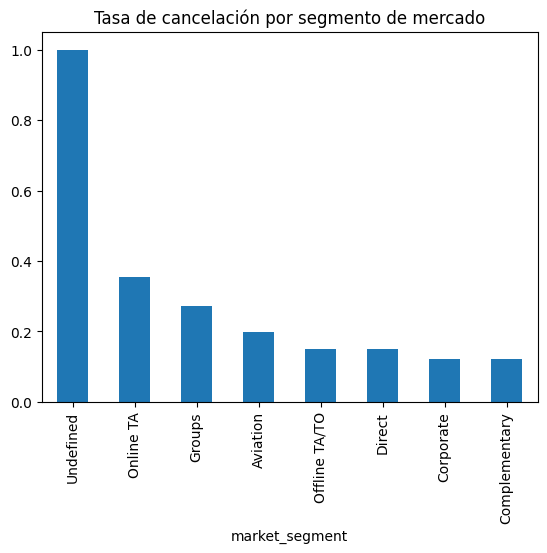

In [26]:
df_eda.groupby("market_segment")["is_canceled"].mean().sort_values(ascending=False).plot(
    kind="bar", title="Tasa de cancelación por segmento de mercado"
)

- `Online TA` es el que más se cancela (35,5 %) y además el más grande (51.285 reservas).
- `Groups` tiene un 27,2 %. `Offline TA/TO` y `Direct` están en el 14,9 % y `Corporate` y `Complementary` en el 12,2 %.
- `Undefined` solo tiene 2 reservas, así que no cuenta.

In [27]:
# Agrupo lead_time en tramos
tramos_lead_time = pd.cut(
    df_eda["lead_time"],
    bins=[-1, 7, 30, 90, 180, 365, 1000],
    labels=["0-7", "8-30", "31-90", "91-180", "181-365", "más de 365"],
)

# Tasa de cancelación por tramo
df_eda.groupby(tramos_lead_time, observed=True)["is_canceled"].agg(["mean", "count"])

,mean,count
lead_time,,
0-7,0.085130,17855
8-30,0.254959,16234
31-90,0.321433,22633
91-180,0.350687,18190
181-365,0.397886,11164
más de 365,0.409982,561


<Axes: title={'center': 'Tasa de cancelación por lead_time (días)'}, xlabel='lead_time'>

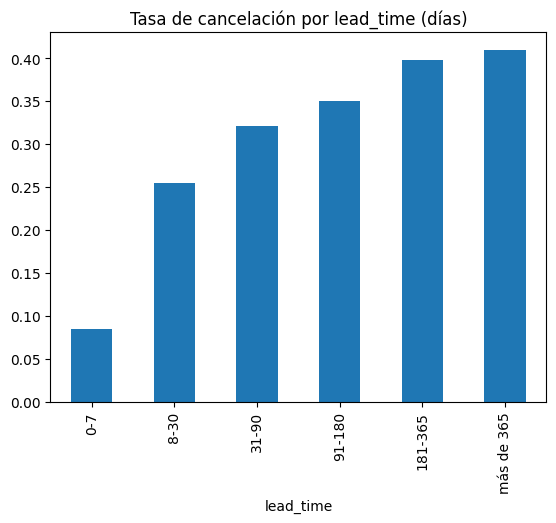

In [28]:
df_eda.groupby(tramos_lead_time, observed=True)["is_canceled"].mean().plot(
    kind="bar", title="Tasa de cancelación por lead_time (días)"
)

Cuanto antes se hace la reserva, más se cancela: del **8,5 %** (0-7 días antes) al **41,0 %** (más de un año antes). Tiene sentido, porque a más tiempo hay más probabilidad de que cambien los planes.

In [29]:
# Tasa de cancelación según cancelaciones anteriores (3 significa "3 o más")
df_eda.groupby(df_eda["previous_cancellations"].clip(upper=3))["is_canceled"].agg(["mean", "count"])

,mean,count
previous_cancellations,,
0,0.268856,84960
1,0.763740,1401
2,0.309091,110
3,0.234940,166


- Casi todas las reservas tienen 0 cancelaciones anteriores (84.960) y se cancelan un 26,9 %.
- Con 1 cancelación anterior se cancela un **76,4 %** (1.401 reservas).
- Con 2 y con 3 o más baja al 30,9 % y 23,5 %, pero son pocas reservas (110 y 166).
- No sube en línea recta, así que esta variable no es tan sencilla como parece.

**Resumen:** las variables que más diferencias muestran son `deposit_type` y `lead_time`, y después `market_segment` y `hotel`.

# E. Fugas de información

## 9. `reservation_status` y `reservation_status_date`
`reservation_status` dice cómo terminó la reserva, así que puede estar "spoileando" `is_canceled`. Lo cruzamos con `is_canceled` para comprobarlo.

In [30]:
# Cruce de reservation_status con el objetivo
pd.crosstab(df_eda["reservation_status"], df_eda["is_canceled"])

is_canceled,0,1
reservation_status,,
Canceled,0,22985
Check-Out,62652,0
No-Show,0,1000


- `Canceled` es siempre 1 (22.985), `Check-Out` es siempre 0 (62.652) y `No-Show` es siempre 1 (1.000, el no-show cuenta como cancelada).
- Coincide al 100 % con `is_canceled`, así que es `is_canceled` con otro nombre. **La elimino.**
- `reservation_status_date` es la fecha en la que cambió ese estado, o sea, información de **después** de la reserva. **También la elimino.**

## 10. `assigned_room_type`
La habitación asignada se decide normalmente cuando llega el cliente. Compruebo cuántas veces es distinta de la reservada y qué pasa con la cancelación.

In [31]:
habitacion_distinta = df_eda["assigned_room_type"] != df_eda["reserved_room_type"]
df_eda.groupby(habitacion_distinta)["is_canceled"].agg(["mean", "count"])

,mean,count
False,0.316004,73977
True,0.048025,12660


- Solo 12.660 reservas (14,6 %) tienen una habitación distinta, y de esas solo se cancela un **4,8 %**, frente al 31,6 % de las demás.
- Parece que la habitación se asigna (o se cambia) cuando el cliente llega. No puedo asegurarlo con estos datos, pero lo que se ve apunta a eso.
- Si es así, esa información no la tendríamos cuando queremos predecir y le estaríamos dando una pista al modelo. Por eso **la elimino**: solo uso columnas que se conocen en el momento de predecir.

**Columnas que elimino por fuga de información:** `reservation_status`, `reservation_status_date` y `assigned_room_type`.

# Conclusiones del EDA

- **Columnas que elimino:** `reservation_status`, `reservation_status_date` (fuga de información) y `assigned_room_type` (fuga probable).
- **Filas que elimino:** duplicados, el `adr` negativo y el de 5400, reservas sin huéspedes y reservas de 0 noches. Pasamos de 119.390 a 86.637 filas.
- **Nulos:** `children` a 0, `country` a "Unknown" (agrupando los países poco frecuentes en "Other"), `agent` como categoría "Sin agente" y `company` como `tiene_empresa` (1 o 0).
- **Objetivo:** las canceladas son el 27,7 %, así que hay desbalanceo y accuracy sola no sirve.
- **Variables que más diferencias muestran:** `deposit_type` y `lead_time`, y después `market_segment` y `hotel`.
- **Para la reflexión del informe:** `Non Refund` se cancela un 94,7 %, que es raro, y no sabemos si los duplicados eran reservas reales distintas.